In [1]:
# Import required libraries

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

from sklearn.decomposition import PCA

import warnings
warnings.filterwarnings('ignore')

print("All libraries imported successfully!")

All libraries imported successfully!


In [2]:
# Load Wholesale Customers dataset

url = "https://archive.ics.uci.edu/ml/machine-learning-databases/00292/Wholesale%20customers%20data.csv"

data = pd.read_csv(url)

print("Dataset loaded successfully!")

data.head()

Dataset loaded successfully!


,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
0,2,3,12669,9656,7561,214,2674,1338
1,2,3,7057,9810,9568,1762,3293,1776
2,2,3,6353,8808,7684,2405,3516,7844
3,1,3,13265,1196,4221,6404,507,1788
4,2,3,22615,5410,7198,3915,1777,5185


In [3]:
# Display dataset information

print("Dataset Shape:", data.shape)

print("\nDataset Information:")
data.info()

print("\nStatistical Summary:")
display(data.describe())

print("\nMissing Values:")
print(data.isnull().sum())

Dataset Shape: (440, 8)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 440 entries, 0 to 439
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   Channel           440 non-null    int64
 1   Region            440 non-null    int64
 2   Fresh             440 non-null    int64
 3   Milk              440 non-null    int64
 4   Grocery           440 non-null    int64
 5   Frozen            440 non-null    int64
 6   Detergents_Paper  440 non-null    int64
 7   Delicassen        440 non-null    int64
dtypes: int64(8)
memory usage: 27.6 KB

Statistical Summary:


,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
count,440.000000,440.000000,440.000000,440.000000,440.000000,440.000000,440.000000,440.000000
mean,1.322727,2.543182,12000.297727,5796.265909,7951.277273,3071.931818,2881.493182,1524.870455
std,0.468052,0.774272,12647.328865,7380.377175,9503.162829,4854.673333,4767.854448,2820.105937
min,1.000000,1.000000,3.000000,55.000000,3.000000,25.000000,3.000000,3.000000
25%,1.000000,2.000000,3127.750000,1533.000000,2153.000000,742.250000,256.750000,408.250000
50%,1.000000,3.000000,8504.000000,3627.000000,4755.500000,1526.000000,816.500000,965.500000
75%,2.000000,3.000000,16933.750000,7190.250000,10655.750000,3554.250000,3922.000000,1820.250000
max,2.000000,3.000000,112151.000000,73498.000000,92780.000000,60869.000000,40827.000000,47943.000000



Missing Values:
Channel             0
Region              0
Fresh               0
Milk                0
Grocery             0
Frozen              0
Detergents_Paper    0
Delicassen          0
dtype: int64


In [4]:
# Select features for clustering

X = data[
    [
        'Channel',
        'Region',
        'Fresh',
        'Milk',
        'Grocery',
        'Frozen',
        'Detergents_Paper',
        'Delicassen'
    ]
]

print("Selected Features:")
display(X.head())

Selected Features:


,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
0,2,3,12669,9656,7561,214,2674,1338
1,2,3,7057,9810,9568,1762,3293,1776
2,2,3,6353,8808,7684,2405,3516,7844
3,1,3,13265,1196,4221,6404,507,1788
4,2,3,22615,5410,7198,3915,1777,5185


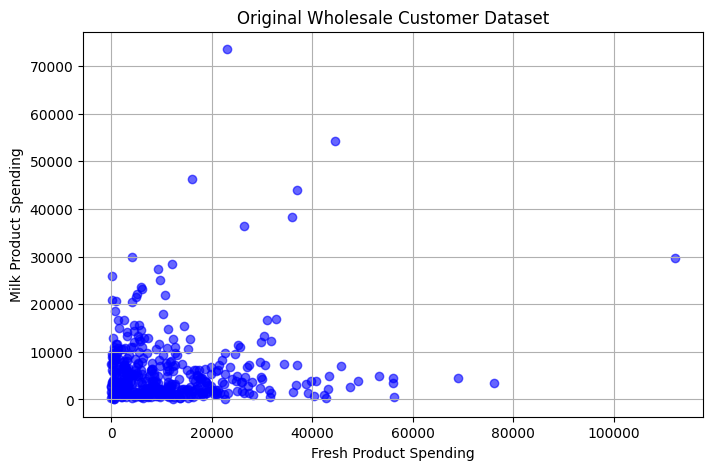

In [5]:
# Visualize customer data

plt.figure(figsize=(8, 5))

plt.scatter(
    X['Fresh'],
    X['Milk'],
    color='blue',
    alpha=0.6
)

plt.title("Original Wholesale Customer Dataset")
plt.xlabel("Fresh Product Spending")
plt.ylabel("Milk Product Spending")

plt.grid(True)
plt.show()

In [6]:
# Standardize the dataset

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

print("Data standardized successfully!")

print("Scaled Dataset Shape:", X_scaled.shape)

Data standardized successfully!
Scaled Dataset Shape: (440, 8)


In [7]:
# Apply K-Means++ clustering

kmeans = KMeans(
    n_clusters=2,
    init='k-means++',
    n_init=10,
    random_state=42
)

kmeans.fit(X_scaled)

print("K-Means clustering completed!")

print("Inertia:", kmeans.inertia_)

K-Means clustering completed!
Inertia: 2599.387384912305


In [8]:
# Calculate inertia for different cluster values

SSE = []

for k in range(1, 20):

    kmeans = KMeans(
        n_clusters=k,
        init='k-means++',
        n_init=10,
        random_state=42
    )

    kmeans.fit(X_scaled)

    SSE.append(kmeans.inertia_)

print("Inertia values calculated successfully!")

Inertia values calculated successfully!


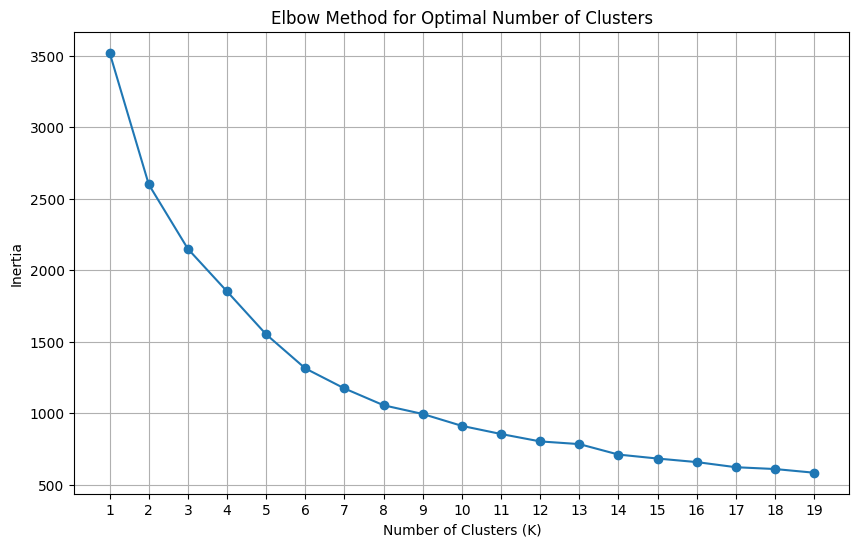

In [9]:
# Visualize the Elbow Method

plt.figure(figsize=(10, 6))

plt.plot(
    range(1, 20),
    SSE,
    marker='o'
)

plt.title("Elbow Method for Optimal Number of Clusters")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")

plt.xticks(range(1, 20))
plt.grid(True)

plt.show()

In [10]:
# Apply final K-Means model

kmeans = KMeans(
    n_clusters=5,
    init='k-means++',
    n_init=10,
    random_state=42
)

pred = kmeans.fit_predict(X_scaled)

# Add cluster labels to original dataset

data['Cluster'] = pred

print("Final clustering completed successfully!")

data.head()

Final clustering completed successfully!


,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen,Cluster
0,2,3,12669,9656,7561,214,2674,1338,1
1,2,3,7057,9810,9568,1762,3293,1776,1
2,2,3,6353,8808,7684,2405,3516,7844,1
3,1,3,13265,1196,4221,6404,507,1788,3
4,2,3,22615,5410,7198,3915,1777,5185,1


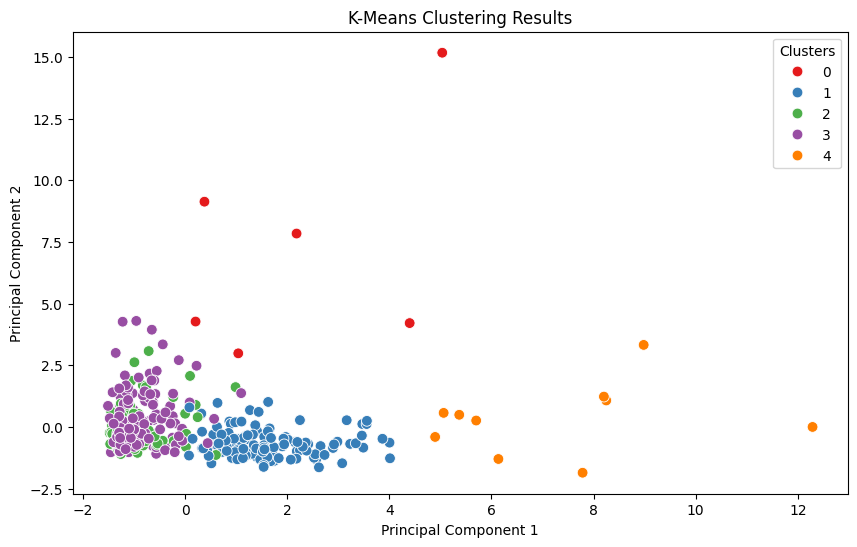

In [14]:
# Reduce dimensions using PCA

pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_scaled)

# Create visualization dataframe

visual_data = pd.DataFrame({
    'PCA1': X_pca[:, 0],
    'PCA2': X_pca[:, 1],
    'Cluster': pred
})

# Plot clusters

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=visual_data,
    x='PCA1',
    y='PCA2',
    hue='Cluster',
    palette='Set1',
    s=60
)

plt.title("K-Means Clustering Results")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.legend(title="Clusters")

plt.show()

In [13]:
# Calculate Silhouette Score

score = silhouette_score(X_scaled, pred)

print("Silhouette Score:", round(score, 4))

Silhouette Score: 0.3529


In [15]:
# Display cluster information

print("Number of Clusters:", data['Cluster'].nunique())

print("\nCluster Distribution:")
print(data['Cluster'].value_counts().sort_index())

print("\nFinal Model Inertia:")
print(kmeans.inertia_)

print("\nCluster Mean Values:")
display(data.groupby('Cluster').mean())

Number of Clusters: 5

Cluster Distribution:
Cluster
0      6
1    126
2     91
3    207
4     10
Name: count, dtype: int64

Final Model Inertia:
1551.6677076665608

Cluster Mean Values:


,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
Cluster,,,,,,,,
0,1.166667,2.833333,44940.666667,22179.166667,17187.000000,21831.166667,2758.000000,17908.000000
1,2.000000,2.674603,8130.031746,8874.071429,14139.150794,1339.476190,6104.936508,1542.706349
2,1.054945,1.307692,12183.945055,3254.714286,4130.923077,3458.252747,860.263736,1149.934066
3,1.000000,3.000000,13129.057971,3168.526570,3635.864734,3413.729469,749.038647,1135.468599
4,2.000000,2.500000,15964.900000,34708.500000,48536.900000,3054.600000,24875.200000,2942.800000


In [16]:
# Save clustering results

data.to_csv(
    'K_Means_Clustering_Results.csv',
    index=False
)

print("Results saved successfully!")

Results saved successfully!


In [17]:
from google.colab import files

files.download('K_Means_Clustering_Results.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>